In [1]:
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = "by_wild_type.csv.gz"

In [2]:
#Load the dataset through pandas

df = pd.read_csv(DATA_PATH, compression='gzip')
print(f"{df.shape[0]} rows and {df.shape[1]} columns")
print(df.dtypes)
df.head()

884 rows and 4 columns
sequence        str
target        int64
set             str
validation     bool
dtype: object


,sequence,target,set,validation
0,MSNPNPFQTTLGTDAQWVVFAVMALAAIVFSIAVQFRPLPLRLTYY...,525,train,True
1,MSNPNPFQTTLGTDAQWVVFAVMALAAIVFSIAVQFRPLPLRLTYY...,523,train,True
2,MSNPNPFQTTLGTDAQWVVFAVMALAAIVFSIAVQFRPLPLRLTYY...,523,train,True
3,MSNPNPFQTTLGTDAQWVVFAVMALAAIVFSIAVQFRPLPLRLTYY...,502,train,True
4,MDPIALTAAVGADLLGDGRPETLWLGIGTLLMLIGTFYFIVKGWGV...,558,test,False


In [3]:
#as per the format docs on FLIP2, val rows appear inside set = "train" with val flag set to True

#validation may load as bool or strings not sure
df["validation"] = df["validation"].astype(str).str.lower().eq("true")

pd.crosstab(df["set"], df["validation"])

validation,False,True
set,,
test,184,0
train,584,116


In [4]:
df["split"] = df["set"]
df.loc[df["validation"], "split"] = "val"
df["split"].value_counts()

split
train    584
test     184
val      116
Name: count, dtype: int64

In [5]:
#The paper reports means of around 539.7 on train 531.7 on val 534.4 on test
#we just need to check that the means are similar to those reported in the paper
df.groupby("split")["target"].describe().round(1)


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
test,184.0,534.4,32.2,436.0,522.8,539.5,555.0,589.0
train,584.0,539.7,31.3,460.0,521.0,533.0,556.2,622.0
val,116.0,531.7,25.6,455.0,519.8,529.0,548.0,590.0


In [6]:
#Determine sequence length to see if one-hot and padding is feasible
#else we need some form of alignment or embedding to handle variable length sequences

df["length"] = df["sequence"].str.len()
df.groupby("split")["length"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
test,184.0,272.9,29.9,227.0,257.0,261.5,282.8,365.0
train,584.0,272.1,20.4,235.0,249.0,280.0,280.0,328.0
val,116.0,270.7,27.5,230.0,250.0,258.0,296.0,359.0


In [7]:
alphabet = Counter("".join(df["sequence"]))
standard = set("ACDEFGHIKLMNPQRSTVWY")
odd = {aa: n for aa, n in alphabet.items() if aa not in standard}
print(f"Distinct residues: {len(alphabet)}")
print(f"Non-standard residues: {odd or 'none'}")

Distinct residues: 20
Non-standard residues: none


In [8]:
#Check for leakages and label noise by looking at the distribution of targets for each split


seqs = {s: set(g["sequence"]) for s, g in df.groupby("split")}
names = list(seqs)
for i, a in enumerate(names):
    for b in names[i + 1:]:
        print(f"exact-sequence overlap {a} <-> {b}: {len(seqs[a] & seqs[b])}")

print(f"\nRows sharing a sequence with another row: {df['sequence'].duplicated(keep=False).sum()}")

exact-sequence overlap test <-> train: 0
exact-sequence overlap test <-> val: 0
exact-sequence overlap train <-> val: 0

Rows sharing a sequence with another row: 12


In [9]:
conflicts = (
    df.groupby("sequence")["target"].agg(["count", "min", "max"])
    .query("count > 1")
)
conflicts["spread_nm"] = conflicts["max"] - conflicts["min"]
print(f"Duplicated sequences: {len(conflicts)}")
conflicts.sort_values("spread_nm", ascending=False).head(10)

Duplicated sequences: 6


,count,min,max,spread_nm
sequence,,,,
MKLLLILGSVIALPTFAAGGGDLDASDYTGVSFWLVTAALLASTVFFFVERDRVSAKWKTSLTVSGLVTGIAFWHYMYMRGVWIETGDSPTVFRYIDWLLTVPLQICEFYLILAAATNVAGSLFKKLLVGSLVMLVFGYMGEAGIMAAWPAFIIGCLAWVYMIYELWAGEGKSACNTASPAVQSAYNTMMYIIIFGWAIYPVGYFTGYLMGDGGSALNLNLIYNLADFVNKILFGLIIWNVAVKESSNA,2,498,517,19
MTQELGNANFENFIGATEGFSEIAYQFTSHILTLGYAVMLAGLLYFILTIKNVDKKFQMSNILSAVVMVSAFLLLYAQAQNWTSSFTFNEEVGRYFLDPSGDLFNNGYRYLNWLIDVPMLLFQILFVVSLTTSKFSSVRNQFWFSGAMMIITGYIGQFYEVSNLTAFLVWGAISSAFFFHILWVMKKVINEGKEGISPAGQKILSNIWILFLISWTLYPGAYLMPYLTGVDGFLYSEDGVMARQLVYTIADVSSKVIYGVLLGNLAITLSKNKELVEANS,2,524,525,1
MTQELGNANFENFIGATEGFSEIAYQFTSHILTLGYAVMLAGLLYFILTIKNVDKKFQMSNILSAVVMVSAFLLYYAQAQNWTSSFTFNEEVGRYFLDPSGDLFNNGYRYLNWLIDVPMLLFQILFVVSLTTSKFSSVRNQFWFSGAMMIITGYIGQFYEVSNLTAFLVWGAISSAFFFHILWVMKKVINEGKEGISPAGQKILSNIWILFLISWTLYPGAYLMPYLTGVDGFLYSEDGVMARQLVYTIADVSSKVIYGVLLGNLAITLSKNKELVEANS,2,530,530,0
MTQELGNANFENFIGATEGFSEIAYQFTSHILTLGYAVMLAGLLYFILTIKNVDKKFQMSNILSAVVMVSAGLLLYAQAQNWTSSFTFNEEVGRYFLDPSGDLFNNGYRYLNWLIDVPMLLFQILFVVSLTTSKFSSVRNQFWFSGAMMIITGYIGQFYEVSNLTAFLVWGAISSAFFFHILWVMKKVINEGKEGISPAGQKILSNIWILFLISWTLYPGAYLMPYLTGVDGFLYSEDGVMARQLVYTIADVSSKVIYGVLLGNLAITLSKNKELVEANS,2,525,525,0
MTQELGNANFENFIGATEGFSEIAYQFTSHILTLGYAVMLAGLLYFILTIKNVDKKFQMVNILSAVVMVSAFLLLYAQAQNWTSSFTFNEEVGRYFLDPSGDLFNNGYRYLNWLIDVPMLLFQILFVVSLTTSKFSSVRNQFWFSGAMMIITGYIGQFYEVSNLTAFLVWGAISSAFFFHILWVMKKVINEGKEGISPAGQKILSNIWILFLISWTLYPGAYLMPYLTGVDGFLYSEDGVMARQLVYTIADVSSKVIYGVLLGNLAITLSKNKELVEANS,2,523,523,0
MTQELGNANFENFIGATEGFSEITYQFTSHILTLGYAVMLAGLLYFILTIKNVDKKFQMSNILSAVVMVSAFLLLYAQAQNWTSSFTFNEEVGRYFLDPSGDLFNNGYRYLNWLIDVPMLLFQILFVVSLTTSKFSSVRNQFWFSGAMMIITGYIGQFYEVSNLTAFLVWGAISSAFFFHILWVMKKVINEGKEGISPAGQKILSNIWILFLISWTLYPGAYLMPYLTGVDGFLYSEDGVMARQLVYTIADVSSKVIYGVLLGNLAITLSKNKELVEANS,2,525,525,0


Odd coincidence that these sequences occur exactly twice

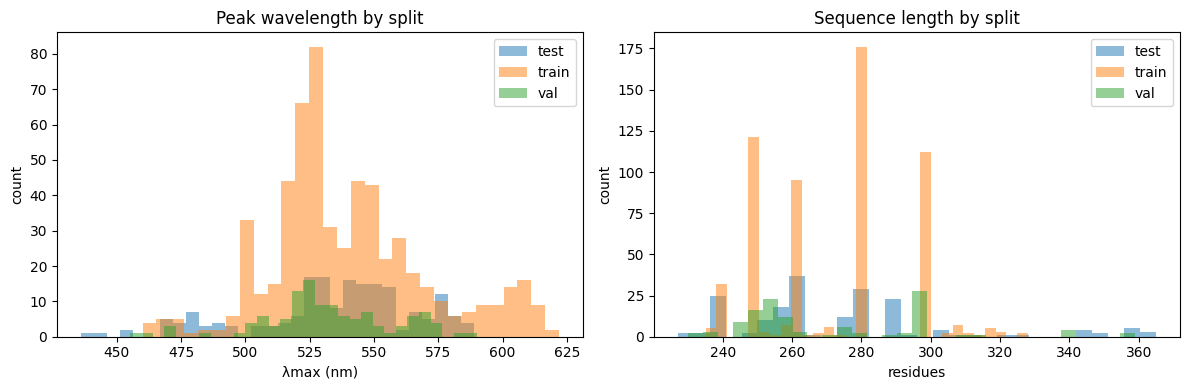

In [10]:
#Basic Plots
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for s, g in df.groupby("split"):
    axes[0].hist(g["target"], bins=30, alpha=0.5, label=s)
    axes[1].hist(g["length"], bins=30, alpha=0.5, label=s)
axes[0].set(title="Peak wavelength by split", xlabel="λmax (nm)", ylabel="count")
axes[1].set(title="Sequence length by split", xlabel="residues", ylabel="count")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

Findings:
1. The dataset is clean already but theres an issue with counts per fmaily
    - train only has 584 rows freom only 5 wild types, about 117 rows per family
    - val has 34 wild types, much lower 3 per family
    -test has 36 wild types, around 5 per family
Whatever model we feed its going to see many variations of a few proteins then gets tested on a lot of proteins it has never seen. Cross family generalization effective n is closert to the 5 wild types than 584.
2. Train lengths fall under a few sharp spikes, since mutants keep the parent's length, this means each spike is essentially one family. 
    - one hot encoding and padding is out
    - High likelihood of shortcuts within the model, lengths is as good an indicator for family as a label is here.
3. Target distributions differ a lot in shape not just rain, train has a distinctly red cluster, test has blues.
4. There are 6 duplicated sequences (12 samples) asll in the same split, gives us a notable noise floor.